<center><h1>Last_First_HW5</h1></center>
<br>
<br>

Name: Tony Chen
<br>
Github Username: tchenusc
<br>
USC ID: 9747866232

## 1. Decision Trees as Interpretable Models

Import packages

In [39]:
%pip install "xgboost==1.7.6"
import ctypes, os, sklearn
ctypes.CDLL(os.path.join(os.path.dirname(sklearn.__file__), '.dylibs', 'libomp.dylib'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### (a) Obtain Data

Get the Accute Inamations Data Set

In [ ]:
columnNames = ['temperature', 'nausea', 'lumbarPain', 'urinePushing', 'micturitionPains',
               'urethraBurning', 'bladderInflammation', 'nephritis']
diagnosisDf = pd.read_csv('../data/diagnosis.data', sep='\t', encoding='utf-16', decimal=',',
                          header=None, names=columnNames)

for columnName in columnNames[1:]:
    diagnosisDf[columnName] = diagnosisDf[columnName].replace({'yes': 1, 'no': 0})

featureNames = columnNames[:6]
diagnosisFeatures = diagnosisDf[featureNames]

diagnosisLabels = []
for rowIndex in range(len(diagnosisDf)):
    bladderValue = diagnosisDf['bladderInflammation'][rowIndex]
    nephritisValue = diagnosisDf['nephritis'][rowIndex]
    diagnosisLabels.append('bladder=' + str(bladderValue) + ', nephritis=' + str(nephritisValue))

diagnosisDf.head()

,temperature,nausea,lumbarPain,urinePushing,micturitionPains,urethraBurning,bladderInflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

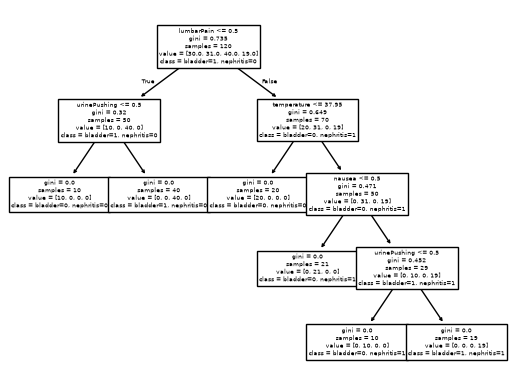

In [41]:
fullTree = DecisionTreeClassifier(random_state=42)
fullTree.fit(diagnosisFeatures, diagnosisLabels)

plot_tree(fullTree, feature_names=featureNames, class_names=list(fullTree.classes_))
plt.show()

### (c) Convert the decision rules

```
1. if lumbarPain <= 0.5 and urinePushing <= 0.5
       then no bladder inflammation, no nephritis
2. if lumbarPain <= 0.5 and urinePushing > 0.5
       then bladder inflammation, no nephritis
3. if lumbarPain > 0.5 and temperature <= 37.95
       then no bladder inflammation, no nephritis
4. if lumbarPain > 0.5 and temperature > 37.95 and nausea <= 0.5
       then no bladder inflammation, nephritis
5. if lumbarPain > 0.5 and temperature > 37.95 and nausea > 0.5 and urinePushing <= 0.5
       then no bladder inflammation, nephritis
6. if lumbarPain > 0.5 and temperature > 37.95 and nausea > 0.5 and urinePushing > 0.5
       then bladder inflammation, nephritis
```

### (d) Cost-complexity pruning

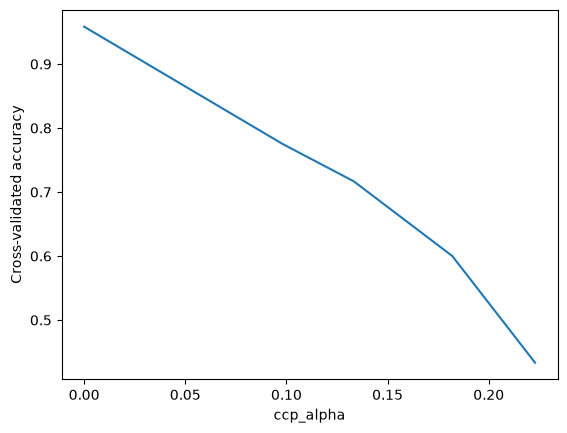

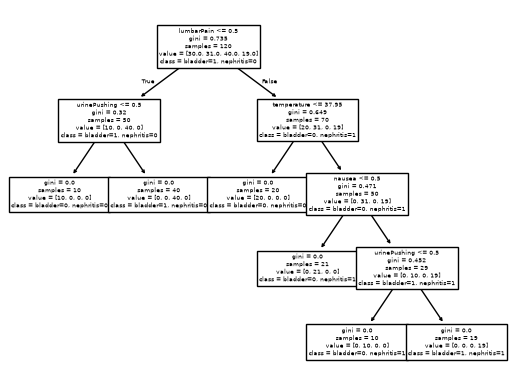

The original tree has the best cross-validated accuracy at around 96%
Therefore, we choose 0 as our alpha and the minmum tree is the same as part b
The decision rules, similarly, are the same as in part c.


In [42]:
alphaCandidates = fullTree.cost_complexity_pruning_path(diagnosisFeatures, diagnosisLabels).ccp_alphas

cvAccuracies = []
for alpha in alphaCandidates:
    candidateTree = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    scores = cross_val_score(candidateTree, diagnosisFeatures, diagnosisLabels, cv=5)
    cvAccuracies.append(scores.mean())

plt.plot(alphaCandidates, cvAccuracies)
plt.xlabel('ccp_alpha')
plt.ylabel('Cross-validated accuracy')
plt.show()

bestAlpha = alphaCandidates[0]
bestAccuracy = cvAccuracies[0]
for i in range(len(alphaCandidates)):
    if cvAccuracies[i] > bestAccuracy:
        bestAccuracy = cvAccuracies[i]
        bestAlpha = alphaCandidates[i]
#print(bestAlpha)

prunedTree = DecisionTreeClassifier(random_state=42, ccp_alpha=bestAlpha)
prunedTree.fit(diagnosisFeatures, diagnosisLabels)

plot_tree(prunedTree, feature_names=featureNames, class_names=list(prunedTree.classes_))
plt.show()

#print(alphaCandidates.round(3))
print('The original tree has the best cross-validated accuracy at around 96%')
print('Therefore, we choose 0 as our alpha and the minmum tree is the same as part b')
print('The decision rules, similarly, are the same as in part c.')

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [43]:
attributeNames = []
namesFile = open('../data/communities.names')
for line in namesFile:
    if line.startswith('@attribute'):
        parts = line.split()
        attributeNames.append(parts[1])
namesFile.close()

crimeDf = pd.read_csv('../data/communities.data', header=None, names=attributeNames, na_values='?')

trainDf = crimeDf.iloc[:1495]
testDf = crimeDf.iloc[1495:]

### (b) Missing values

In [44]:
nonPredictiveColumns = ['state', 'county', 'community', 'communityname', 'fold']
trainDf = trainDf.drop(columns=nonPredictiveColumns)
testDf = testDf.drop(columns=nonPredictiveColumns)

trainDf = trainDf.fillna(trainDf.mean())
testDf = testDf.fillna(testDf.mean())

targetName = 'ViolentCrimesPerPop'
xTrain = trainDf.drop(columns=targetName)
yTrain = trainDf[targetName]
xTest = testDf.drop(columns=targetName)
yTest = testDf[targetName]

crimeDf = pd.concat([trainDf, testDf])
featureDf = crimeDf.drop(columns=targetName)

### (c) Plot a correlation matrix

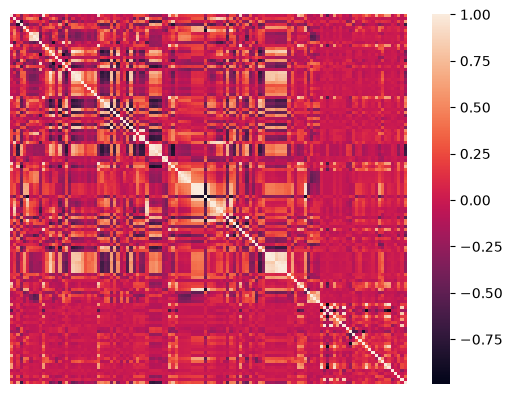

In [45]:
sns.heatmap(crimeDf.corr(), xticklabels=False, yticklabels=False)
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [46]:
coefficientOfVariation = (featureDf.std() / featureDf.mean()).sort_values(ascending=False)
coefficientOfVariation.head(15)

NumStreet              4.407702
NumInShelters          3.485481
NumIlleg               2.994196
NumImmig               2.900497
LemasPctOfficDrugUn    2.555266
NumUnderPov            2.304970
population             2.203503
numbUrban              2.001744
HousVacant             1.958780
LandArea               1.678031
racePctHisp            1.614278
PctNotSpeakEnglWell    1.459067
PctUsePubTrans         1.416673
racepctblack           1.410920
racePctAsian           1.359162
dtype: float64

### (e) Scatter plots and box plots for highest CV features

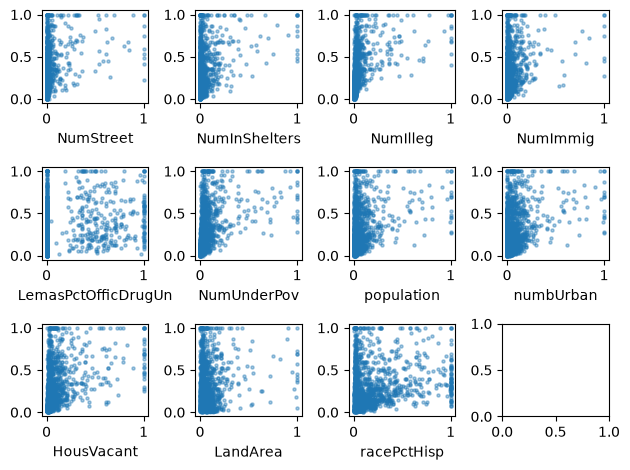

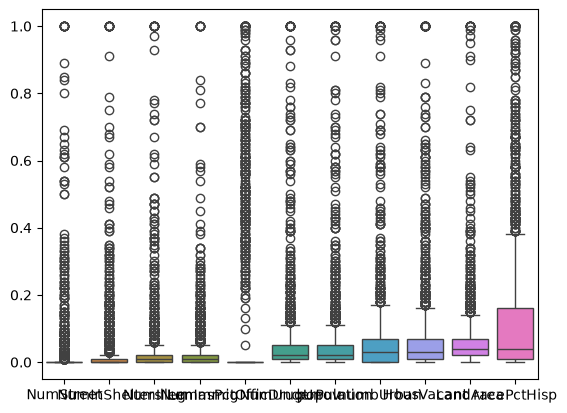

No, we cannot draw much conclusions about the significance of these features.
From the scatter plots, we can see that there is no clear positive or negative trend between our data.
And more notably, we can observe there is actually a lot of data near zero or near both zero and one in some cases.
This shows that there is not a lot of variance in the data, and does not support there being a significance for those features.


In [47]:
topCvFeatures = coefficientOfVariation.head(11).index
fig, axes = plt.subplots(3, 4)
for i in range(11):
    featureName = topCvFeatures[i]
    row = i // 4
    column = i % 4
    axes[row, column].scatter(crimeDf[featureName], crimeDf[targetName], s=5, alpha=0.4)
    axes[row, column].set_xlabel(featureName)
plt.tight_layout()
plt.show()

sns.boxplot(data=crimeDf[topCvFeatures])
plt.show()

print('No, we cannot draw much conclusions about the significance of these features.')
print('From the scatter plots, we can see that there is no clear positive or negative trend between our data.')
print('And more notably, we can observe there is actually a lot of data near zero or near both zero and one in some cases.')
print('This shows that there is not a lot of variance in the data, and does not support there being a significance for those features.')

### (f) Fit a linear model

In [48]:
linearModel = LinearRegression().fit(xTrain, yTrain)
print(mean_squared_error(yTest, linearModel.predict(xTest)))

0.01811246202653348


### (g) Fit a ridge regression model

In [49]:
ridgeModel = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(xTrain, yTrain)
print(mean_squared_error(yTest, ridgeModel.predict(xTest)))

0.017615775400148


### (h) Fit a LASSO model

In [50]:
lassoModel = LassoCV(cv=5, max_iter=10000).fit(xTrain, yTrain)
lassoPredictions = lassoModel.predict(xTest)
print('Test Error:', mean_squared_error(yTest, lassoPredictions))

selectedVariables = []
for i in range(len(xTrain.columns)):
    if lassoModel.coef_[i] != 0:
        selectedVariables.append(xTrain.columns[i])
print('Variables selected:', selectedVariables)
print()

# same thing again but with standardized variables
scaler = StandardScaler()
scaler.fit(xTrain)
xTrainScaled = scaler.transform(xTrain)
xTestScaled = scaler.transform(xTest)

standardLassoModel = LassoCV(cv=5, max_iter=10000).fit(xTrainScaled, yTrain)
standardPredictions = standardLassoModel.predict(xTestScaled)
print("STANDARDIZED:")
print('Test Error:', mean_squared_error(yTest, standardPredictions))

standardSelectedVariables = []
for i in range(len(xTrain.columns)):
    if standardLassoModel.coef_[i] != 0:
        standardSelectedVariables.append(xTrain.columns[i])
print('Variables selected:', standardSelectedVariables)
print()

print('The test errors obtained from standarization and the lack thereof are pretty much equivalent, with the LASSO model being marginally better.')

Test Error: 0.017735383043771764
Variables selected: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctBornSameState', 

### (i) Fit a PCR model

In [51]:
pca = PCA()
xTrainPca = pca.fit_transform(xTrain)
xTestPca = pca.transform(xTest)

bestM = 1
bestCvError = 1000
for m in range(1, xTrain.shape[1] + 1):
    scores = cross_val_score(LinearRegression(), xTrainPca[:, :m], yTrain, cv=5,
                             scoring='neg_mean_squared_error')
    cvError = -scores.mean()
    if cvError < bestCvError:
        bestCvError = cvError
        bestM = m

pcrModel = LinearRegression().fit(xTrainPca[:, :bestM], yTrain)
print('Best M:', bestM)
print('Test Error:', mean_squared_error(yTest, pcrModel.predict(xTestPca[:, :bestM])))

Best M: 96
Test Error: 0.018445086212504538


### (j) Fit a boosting tree

In [52]:
alphaValues = [0, 0.01, 0.1, 1, 10]
bestRegAlpha = 0
bestBoostingError = 1000
for alphaValue in alphaValues:
    boostingCandidate = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3,
                                     random_state=42, reg_alpha=alphaValue)
    scores = cross_val_score(boostingCandidate, xTrain, yTrain, cv=5, scoring='neg_mean_squared_error')
    boostingError = -scores.mean()
    if boostingError < bestBoostingError:
        bestBoostingError = boostingError
        bestRegAlpha = alphaValue

boostingModel = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3,
                             random_state=42, reg_alpha=bestRegAlpha).fit(xTrain, yTrain)
print('Regularization term:', bestRegAlpha)
print('Test Error:', mean_squared_error(yTest, boostingModel.predict(xTest)))

Regularization term: 1
Test Error: 0.016714509201090192
